In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings
from IPython.display import display
warnings.simplefilter("ignore")
%matplotlib inline

In [23]:
data = pd.read_csv("Food_Delivery_Times.csv")
display(data.shape)
data.head()

(1000, 9)

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


ВЫВОДЫ:

1 объект - 1 заказ еды;

Order_ID: уникальный идентификатор каждого заказа.

Distance_km: расстояние доставки в километрах (от 0,6 до 20).

Weather: погодные условия во время доставки.

Traffic_Level: уровень загруженности дорог.

Time_of_Day: время доставки (утро, день, вечер, ночь).

Vehicle_Type: тип транспортного средства, используемого для доставки.

Preparation_Time_min: Время, необходимое для подготовки заказа, в минутах (от 5 до 29).

Courier_Experience_yrs: Опыт работы курьера в годах (от 0 до 9).

Delivery_Time_min: Общее время доставки в минутах (от 8 до 153).

Ожидаемые зависимости: время суток влияет на загруженность дорог; трафик, погода, опыт курьера, расстояние влияют на время доставки; время приготовления прибавляется к общему времени доставки.

In [24]:
# display(data.info())
# пропуски
null = data.isna().sum()
display(pd.DataFrame({"пропусков": null})[null > 0])
# дубликаты
print('Полных дубликатов:', data.duplicated().sum())

,пропусков
Weather,30
Traffic_Level,30
Time_of_Day,30
Courier_Experience_yrs,30


Полных дубликатов: 0


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

data_new = data.copy()
num_cols = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs"]
target_col = ["Delivery_Time_min"]
cat_cols = ["Weather", "Traffic_Level", "Time_of_Day", "Vehicle_Type"]

impute_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("target", SimpleImputer(strategy="median"), target_col),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_cols),
], verbose_feature_names_out=False)
impute_preprocess.set_output(transform="pandas")

data_new = impute_preprocess.fit_transform(data_new)
print(data_new.isna().sum())

Distance_km               0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
dtype: int64


In [26]:
for c in cat_cols:
    print(f"\n Распределение {c}")
    print(data_new[c].value_counts())


 Распределение Weather
Weather
Clear    500
Rainy    204
Foggy    103
Snowy     97
Windy     96
Name: count, dtype: int64

 Распределение Traffic_Level
Traffic_Level
Medium    420
Low       383
High      197
Name: count, dtype: int64

 Распределение Time_of_Day
Time_of_Day
Morning      338
Evening      293
Afternoon    284
Night         85
Name: count, dtype: int64

 Распределение Vehicle_Type
Vehicle_Type
Bike       503
Scooter    302
Car        195
Name: count, dtype: int64


In [27]:
data_new["Weather"] = data_new["Weather"].replace({
    "Rainy": "Precipitation", "Snowy": "Precipitation",   # осадки
    "Foggy": "Other", "Windy": "Other"})          # туман и ветер

data_new["Time_of_Day"] = data_new["Time_of_Day"].replace({
    "Evening": "Evening_Night", "Night": "Evening_Night"})

print(data_new["Weather"].value_counts())
print(data_new["Time_of_Day"].value_counts())

Weather
Clear            500
Precipitation    301
Other            199
Name: count, dtype: int64
Time_of_Day
Evening_Night    378
Morning          338
Afternoon        284
Name: count, dtype: int64


In [28]:
target = "Delivery_Time_min"
# Опыт курьера: числовой признак, смотрим корреляцию с временем доставки
print(data_new[["Courier_Experience_yrs", "Distance_km", "Preparation_Time_min", target]].corr()[target].round(3))
# Тип транспорта: смотрим среднее время доставки по типам
print(data_new.groupby("Vehicle_Type")[target].agg(["mean", "count"]).round(1))

# те признаки, которые остаются
for c in ["Weather", "Traffic_Level", "Time_of_Day"]:
    print(data_new.groupby(c)[target].mean().round(1))

data_new = data_new.drop(columns=["Courier_Experience_yrs", "Vehicle_Type"])

Courier_Experience_yrs   -0.089
Distance_km               0.781
Preparation_Time_min      0.307
Delivery_Time_min         1.000
Name: Delivery_Time_min, dtype: float64
              mean  count
Vehicle_Type             
Bike          56.6    503
Car           58.2    195
Scooter       56.0    302
Weather
Clear            53.2
Other            57.5
Precipitation    62.2
Name: Delivery_Time_min, dtype: float64
Traffic_Level
High      64.8
Low       52.9
Medium    56.5
Name: Delivery_Time_min, dtype: float64
Time_of_Day
Afternoon        56.1
Evening_Night    57.0
Morning          57.0
Name: Delivery_Time_min, dtype: float64


Перед дискретизацией проверка числовых признаков, их влияние на время доставки Delivery_Time_min.

Courier_Experience_yrs: корреляция почти нулевая, по сравнению с остальными признаками.

Vehicle_Type: среднее время доставки почти не различается при разных типах транспорта.

Следовательно, эти 2 признака не влияют на время доставки, стрелки от них в графе будут не оправданы, а таблица CPT будет неоправданно большой.

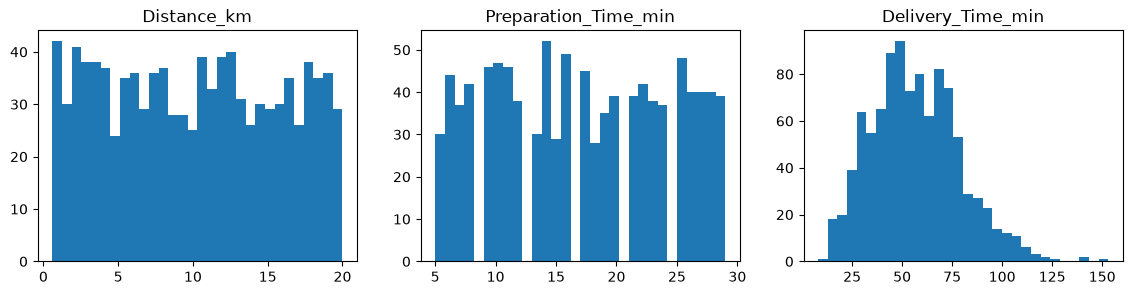

In [29]:
disc_cols = ["Distance_km", "Preparation_Time_min", "Delivery_Time_min"]

fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, c in zip(ax, disc_cols):
    a.hist(data_new[c], bins=30)
    a.set_title(c)
plt.show()

In [30]:
# дискретизация
from sklearn.preprocessing import KBinsDiscretizer

kb = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile")
data_new[disc_cols] = kb.fit_transform(data_new[disc_cols]).astype(int)

for c, edges in zip(disc_cols, kb.bin_edges_):
    print(c, "границы:", edges.round(1))

Distance_km границы: [ 0.6  6.8 13.1 20. ]
Preparation_Time_min границы: [ 5. 13. 21. 29.]
Delivery_Time_min границы: [  8.  45.  66. 153.]


In [31]:
data_new["Distance_km"] = data_new["Distance_km"].map({0: "short", 1: "medium", 2: "long"})
data_new["Preparation_Time_min"] = data_new["Preparation_Time_min"].map({0: "quick", 1: "normal", 2: "slow"})
data_new["Delivery_Time_min"] = data_new["Delivery_Time_min"].map({0: "fast", 1: "normal", 2: "slow"})

data_new.head()

,Distance_km,Preparation_Time_min,Delivery_Time_min,Weather,Traffic_Level,Time_of_Day
0,medium,quick,fast,Other,Low,Afternoon
1,long,normal,slow,Clear,Medium,Evening_Night
2,medium,slow,normal,Other,Low,Evening_Night
3,medium,quick,fast,Precipitation,Medium,Afternoon
4,long,normal,slow,Clear,Low,Morning


In [32]:
# сколько состояний у каждой переменной
for c in data_new.columns:
    print(c, data_new[c].nunique(), sorted(data_new[c].unique()))
print("\n")
# родители Traffic_Level: Weather и Time_of_Day
print(data_new.groupby(["Weather", "Time_of_Day"]).size().unstack())
print("\n")
# родители Delivery_Time_min: Weather, Traffic_Level, Distance_km, Preparation_Time_min
cnt = data_new.groupby(["Weather", "Traffic_Level", "Distance_km", "Preparation_Time_min"]).size()
print(cnt.describe())
print("комбинаций:", len(cnt), "из", 3*3*3*3, "возможных; строк с n<10:", (cnt < 10).sum())

Distance_km 3 ['long', 'medium', 'short']
Preparation_Time_min 3 ['normal', 'quick', 'slow']
Delivery_Time_min 3 ['fast', 'normal', 'slow']
Weather 3 ['Clear', 'Other', 'Precipitation']
Traffic_Level 3 ['High', 'Low', 'Medium']
Time_of_Day 3 ['Afternoon', 'Evening_Night', 'Morning']


Time_of_Day    Afternoon  Evening_Night  Morning
Weather                                         
Clear                140            190      170
Other                 58             67       74
Precipitation         86            121       94


count    81.000000
mean     12.345679
std       7.143459
min       2.000000
25%       7.000000
50%      11.000000
75%      17.000000
max      32.000000
dtype: float64
комбинаций: 81 из 81 возможных; строк с n<10: 34


ВЫВОДЫ:

Пропуски заполнены медианой или модой.

Переменные, у которых было более 3 состояний объединены по смыслу.

Дискретизация: числовые переменные разбиты на 3 группы методом квантилей KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile").

Distance: short до 6.8 км, medium 6.8–13.1 км, long больше 13.1 км;

Preparation: quick до 13 мин, normal 13–21, slow больше 21;

Delivery: fast до 45 мин, normal 45–66, slow больше 66.

Почему такой способ дискретизации: квантили дают группы с примерно равным числом наблюдений, поэтому в группах нет редких состояний. Три группы ограничивают размер таблицы, сохраняя смысл. Границы - это 1/2 и 2/3 квантили.

Количество возможных состояний:
6 переменных по 3 состояния

Достаточность наблюдений:

Для Traffic_Level (родители Weather и Time_of_Day) комбинаций 3·3 = 9 (строк в CPT), в каждой от 58 до 190 наблюдений. Этого достаточно.

Для Delivery_Time_min (родители Weather, Traffic_Level, Distance_km, Preparation_Time_min) комбинаций 3·3·3·3 = 81, и все они встречаются. В среднем 12.3 наблюдения на комбинацию, медиана 11, минимум 2, максимум 32.

В 34 из 81 комбинаций (около 42%) меньше 10 наблюдений. Вероятности в этих строках CPT менее надёжны, поэтому при оценке используется сглаживание.

ПОСТАНОВКА ВОПРОСОВ:

1) Как изменится вероятность медленной доставки, если известно, что расстояние длинное?

    Сравниваем P(Delivery = slow) и P(Delivery = slow | Distance = long). Ожидание: вероятность вырастет в несколько раз, потому что расстояние — основной физический фактор времени доставки.

2) Какова вероятность медленной доставки при одновременно высоких пробках и осадках?

    Считаем P(Delivery = slow | Traffic = High, Weather = Precipitation) и сравниваем с P(Delivery = slow). Ожидание: плохая погода вместе с пробками замедляют доставку сильнее, чем каждый фактор по отдельности.

3) Как дополнительная информация меняет распределение времени доставки?

    Последовательно добавляем сведения (Distance = long, затем Traffic = High и тд.) и смотрим, как меняется распределение fast / normal / slow. Ожидание: с каждым фактом вероятность slow растёт, а fast падает.

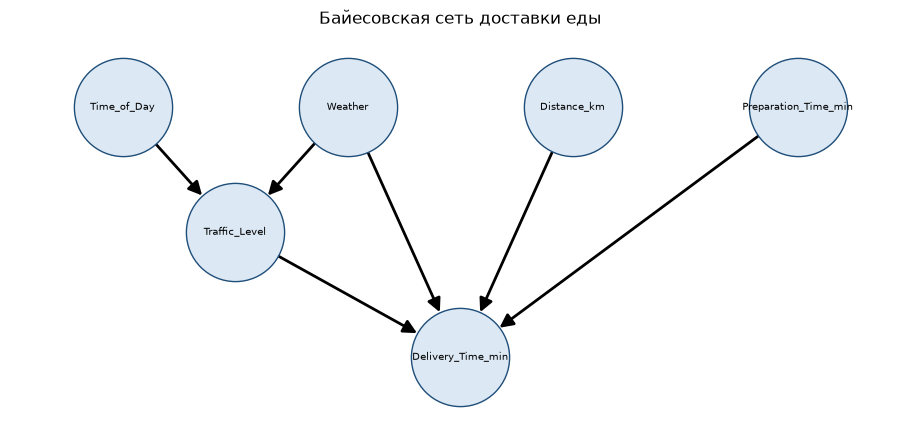

In [33]:
import networkx as nx
# ПОСТРОЕНИЕ ГРАФА
edges = [
    ("Weather", "Traffic_Level"),
    ("Time_of_Day", "Traffic_Level"),
    ("Weather", "Delivery_Time_min"),
    ("Traffic_Level", "Delivery_Time_min"),
    ("Distance_km", "Delivery_Time_min"),
    ("Preparation_Time_min", "Delivery_Time_min"),
]

G = nx.DiGraph(edges)
pos = {"Time_of_Day": (0, 2), "Weather": (2, 2), "Distance_km": (4, 2), "Preparation_Time_min": (6, 2),
       "Traffic_Level": (1, 1), "Delivery_Time_min": (3, 0)}

plt.figure(figsize=(9, 4))
nx.draw(G, pos, with_labels=True, node_size=5000, node_color="#dce9f5",
        edgecolors="#1f4e79", font_size=7, arrowsize=20, width=2)
plt.xlim(-1, 7); plt.ylim(-0.6, 2.6)
plt.title("Байесовская сеть доставки еды")
plt.show()

ВЫВОДЫ:

Граф ориентированный и без циклов (DAG). 

Узлы без родителей: Weather, Time_of_Day, Distance_km, Preparation_Time_min. 

Traffic_Level зависит от погоды и времени суток. 

Delivery_Time_min — итоговая переменная, зависит от погоды, пробок, расстояния и времени приготовления. 

Почему предполагается зависимость и почему такое направление:

 Distance → Delivery. Чем дальше ехать, тем дольше доставка: расстояние физически определяет путь. Расстояние известно до начала доставки, а время доставки — итог, поэтому направление от расстояния ко времени.

 Preparation → Delivery. Время приготовления входит в общее время доставки. Заказ сначала готовят, потом везут, поэтому стрелка идёт от приготовления.

 Traffic → Delivery. Пробки замедляют движение курьера. Загруженность дорог определяется внешними условиями, а не самой доставкой, и от неё зависит время.

 Weather → Delivery. Осадки, туман и ветер снижают скорость курьера.

 Weather → Traffic и Time_of_Day → Traffic. Плохая погода и часы пик увеличивают загрузку дорог. Погода и время суток — внешние факторы, пробки — следствие.

Общий принцип: стрелка идёт от причины/предшествующего фактора к следствию.

Связи Weather → Traffic и Time_of_Day → Traffic выбраны по мыслу (гипотезы).

In [34]:
# условные вероятности
# таблица частот - CPT 
def cpt(child, parents, ess=0):
    # сколько раз встретилась каждая пара: строки = комбинации родителей, столбцы = состояния узла child
    parent_cols = [data_new[p] for p in parents]
    counts = pd.crosstab(parent_cols, data_new[child])

    # сглаживание - эквивалентный размер выборки ess делится на все ячейки таблицы
    alpha = ess / counts.size # num_parent_combos * num_child_states число строк (комбинаций родителей) и число столбцов (состояний child)
    smoothed_counts = counts + alpha

    # для каждой строчки (комбинации родителей); axis=1 - сложить по столбцам (внутри каждой стр)
    row_totals = smoothed_counts.sum(axis=1)

    # каждый элемент стр делим на сумму этой стр (условная вер-ть); axis=0 - выровнять по строкам
    # (КОЛ-ВО НУЖНЫХ ПАР - комбинация родителей + конкретное состояние ребенка) / КОЛ-ВО всех таких комбинаций родителей с разными сост. реб.
    probs = smoothed_counts.div(row_totals, axis=0)
    return probs.round(3)

# узлы без родителей - безусловные вер-ти - доли вариантов в выборке
for c in ["Weather", "Time_of_Day", "Distance_km", "Preparation_Time_min"]:
    print(data_new[c].value_counts(normalize=True).round(3), "\n")

# таблица условных вер-тей для Traffic_Level
display(cpt("Traffic_Level", ["Weather", "Time_of_Day"], ess=5))

#  срезы delivery_cpt.xs - из большой таблицы посмотреть 2 случая
delivery_cpt = cpt(
    "Delivery_Time_min",
    ["Weather", "Traffic_Level", "Distance_km", "Preparation_Time_min"],
    ess=5
)

print("--- Короткое расстояние + быстрое приготовление ---")
display(delivery_cpt.xs(("short", "quick"), level=("Distance_km", "Preparation_Time_min")))

print("--- Длинное расстояние + медленное приготовление ---")
display(delivery_cpt.xs(("long", "slow"), level=("Distance_km", "Preparation_Time_min")))

# как оценка зависит от силы сглаживания
row = ("Other", "High", "medium", "quick")

for ess in [0, 1, 5, 20, 100]:
    tbl = cpt(
        "Delivery_Time_min",
        ["Weather", "Traffic_Level", "Distance_km", "Preparation_Time_min"],
        ess=ess
    )
    # .loc[row] берёт строку с нужной комбинацией родителей
    print(f"ess={ess:3d} ->", tbl.loc[row].to_dict())

Weather
Clear            0.500
Precipitation    0.301
Other            0.199
Name: proportion, dtype: float64 

Time_of_Day
Evening_Night    0.378
Morning          0.338
Afternoon        0.284
Name: proportion, dtype: float64 

Distance_km
long      0.334
medium    0.333
short     0.333
Name: proportion, dtype: float64 

Preparation_Time_min
slow      0.363
quick     0.330
normal    0.307
Name: proportion, dtype: float64 



Traffic_Level                 High    Low  Medium
Weather       Time_of_Day                        
Clear         Afternoon      0.179  0.457   0.364
              Evening_Night  0.164  0.321   0.515
              Morning        0.195  0.359   0.447
Other         Afternoon      0.311  0.276   0.413
              Evening_Night  0.240  0.388   0.373
              Morning        0.137  0.418   0.445
Precipitation Afternoon      0.175  0.453   0.372
              Evening_Night  0.215  0.405   0.380
              Morning        0.245  0.383   0.372

--- Короткое расстояние + быстрое приготовление ---


Delivery_Time_min             fast  normal   slow
Weather       Traffic_Level                      
Clear         High           0.995   0.002  0.002
              Low            0.998   0.001  0.001
              Medium         0.998   0.001  0.001
Other         High           0.853   0.003  0.145
              Low            0.906   0.092  0.002
              Medium         0.995   0.002  0.002
Precipitation High           0.333   0.333  0.333
              Low            0.906   0.002  0.092
              Medium         0.995   0.003  0.003

--- Длинное расстояние + медленное приготовление ---


Delivery_Time_min             fast  normal   slow
Weather       Traffic_Level                      
Clear         High           0.003   0.003  0.993
              Low            0.001   0.104  0.895
              Medium         0.001   0.084  0.915
Other         High           0.007   0.007  0.987
              Low            0.003   0.003  0.993
              Medium         0.002   0.002  0.995
Precipitation High           0.001   0.001  0.997
              Low            0.001   0.060  0.939
              Medium         0.001   0.073  0.926

ess=  0 -> {'fast': 0.0, 'normal': 0.5, 'slow': 0.5}
ess=  1 -> {'fast': 0.002, 'normal': 0.499, 'slow': 0.499}
ess=  5 -> {'fast': 0.01, 'normal': 0.495, 'slow': 0.495}
ess= 20 -> {'fast': 0.037, 'normal': 0.482, 'slow': 0.482}
ess=100 -> {'fast': 0.127, 'normal': 0.436, 'slow': 0.436}


ВЫВОДЫ:

Граф задает разложение совместного распределения как произведение простых условных вероятностей (CPT).

Оценка по частотам:

P(X = x | родители = u) = N(x, u) / N(u),
где N(u) - сколько раз встретилась комбинация родителей u, N(x, u) - сколько раз при этом вершина приняла значение x.

Редкие комбинации родителей могут дать нулевую вероятность - поэтому использовали сглаживание - параметр ess добавляет "условную величину" ко всем ячейкам (Сглаживание Лапласа: к каждому счётчику добавляем одно «воображаемое» наблюдение).

Обобщение сглаживания Лапласа- BDeu с equivalent_sample_size (ESS) - добавка к каждому счётчику = ESS / (число состояний вершины * число комбинаций родителей). Чем больше ESS, тем сильнее вероятности тянутся к равномерным.

Оценка параметров сети: по данным вычислены безусловные вероятности для узлов без родителей (Weather, Time_of_Day, Distance_km, Preparation_Time_min) и таблицы условных вероятностей (CPT) для Traffic_Level и Delivery_Time_min.

Исследование таблиц и влияние сглаживания: при ess = 5 на редкой строке Other + High + medium + quick сглаживание убирает нулевую оценку для fast ([0.0, 0.5, 0.5] при ess = 0 → [0.01, 0.495, 0.495] при ess = 5), при слишком большом ess = 100 распределение заметно сглаживается к равномерному.

Согласование с данными и ожиданиями: при короткой дистанции и быстром приготовлении (short, quick) преобладает fast (0.853–0.998), а при длинной дистанции и медленном приготовлении (long, slow) доминирует slow (0.895–0.997), что соответствует ожиданиям.

Объяснение необычных результатов:

[0.333, 0.333, 0.333] в срезе short + quick при Precipitation + High возникает, потому что в этой комбинации всего 3 наблююдения, по 1 на каждое состояние.

Максимальная доля High трафика в Other + Afternoon (0.311) основана на малом числе наблюдений.

In [ ]:
p_weather = data_new["Weather"].value_counts(normalize=True)
p_time    = data_new["Time_of_Day"].value_counts(normalize=True)
p_dist    = data_new["Distance_km"].value_counts(normalize=True)
p_prep    = data_new["Preparation_Time_min"].value_counts(normalize=True)

traffic_cpt  = cpt("Traffic_Level", ["Weather", "Time_of_Day"], ess=5)
delivery_cpt = cpt("Delivery_Time_min", ["Weather", "Traffic_Level", "Distance_km", "Preparation_Time_min"], ess=5)

# перебор
rows = []
for weather in ["Clear", "Precipitation", "Other"]:
    for time in ["Morning", "Afternoon", "Evening_Night"]:
        for dist in ["short", "medium", "long"]:
            for prep in ["quick", "normal", "slow"]:
                for traf in ["Low", "Medium", "High"]:
                    for delivery in ["fast", "normal", "slow"]:
                        # вероятность ситуации = произведение 6 
                        w = p_weather[weather]                                    # P(погода)
                        t = p_time[time]                                          # P(время суток)
                        dis = p_dist[dist]                                          # P(расстояние)
                        p = p_prep[prep]                                          # P(приготовление)
                        tr = traffic_cpt.loc[(weather, time), traf]             # P(пробки | погода, время суток)
                        d = delivery_cpt.loc[(weather, traf, dist, prep), delivery]  # P(доставка | 4 родителя)

                        rows.append([weather, time, dist, prep, traf, delivery, w * t * dis * p * tr * d])

joint = pd.DataFrame(rows, columns=["Weather", "Time_of_Day", "Distance_km", "Preparation_Time_min",
                                    "Traffic_Level", "Delivery_Time_min", "P"])
print(len(joint), joint["P"].sum().round(3))
display(joint.head())

def query(target, evidence={}, data=None):
    t = joint if data is None else data
    for var, val in evidence.items():          # стр совместимые с evidence
        t = t[t[var] == val]
    return (t.groupby(target)["P"].sum() / t["P"].sum()).round(3)   # складываем и нормируем на сумму

729 1.0


,Weather,Time_of_Day,Distance_km,Preparation_Time_min,Traffic_Level,Delivery_Time_min,P
0,Clear,Morning,short,quick,Low,fast,0.006654
1,Clear,Morning,short,quick,Low,normal,0.000007
2,Clear,Morning,short,quick,Low,slow,0.000007
3,Clear,Morning,short,quick,Medium,fast,0.008285
4,Clear,Morning,short,quick,Medium,normal,0.000008


Граф задает разложение совместного распределения как произведение простых условных вероятностей (CPT).

Общая таблица - список всех возможных ситуаций 3^6 = 729 стр.

Evidence - факт, то что уже известно.
Query - запрос, что хотим узнать.

t.groupby(target)["P"].sum() / t["P"].sum() 

Вер-ть каждого состояния целевого узла при Evidence = (Сумма вер-тей стр с нужным состоянием, где выполняется evidence) / (Сумма вер-тей стр, где выполняется evidence, независимо от состояния)

In [36]:
T = "Delivery_Time_min"
pd.DataFrame({"P(T)": query(T),
              "P(T | Distance=long)": query(T, {"Distance_km": "long"}),
              "P(T | Distance=short)": query(T, {"Distance_km": "short"})})

,P(T),P(T | Distance=long),P(T | Distance=short)
Delivery_Time_min,,,
fast,0.323,0.009,0.773
normal,0.331,0.222,0.193
slow,0.346,0.769,0.034


1) Как изменится вероятность медленной доставки, если известно, что расстояние длинное?

    Ожидание: вероятность вырастет в несколько раз, потому что расстояние — основной физический фактор времени доставки.

Результат:

Информация о длинном расстоянии повышает вероятность медленной доставки примерно в 2 раза, о коротком расстоянии - уменьшает почти в 10 раз, и наоборот, о длинном расстоянии уменьшает вер-ть быстрой доставки, о коротком расстоянии - повышает.

Вывод:

Расстояние является главным фактором, влияющем на целевую переменную.

In [37]:
pd.DataFrame({"P(T)": query(T),
              "P(T | Traffic=High)": query(T, {"Traffic_Level": "High"}),
              "P(T | Weather=Precip)": query(T, {"Weather": "Precipitation"}),
              "P(T | High и Precip)": query(T, {"Traffic_Level": "High", "Weather": "Precipitation"})})

,P(T),P(T | Traffic=High),P(T | Weather=Precip),P(T | High и Precip)
Delivery_Time_min,,,,
fast,0.323,0.213,0.265,0.107
normal,0.331,0.292,0.344,0.316
slow,0.346,0.495,0.391,0.577


2) Какова вероятность медленной доставки при одновременно высоких пробках и осадках?

    Ожидание: плохая погода вместе с пробками замедляют доставку сильнее, чем каждый фактор по отдельности.

Результат:

Высокие пробки добавляют к простой вер-ти медленной доставки + 0,149; Осадки - +0,045; Их комбинация - 0,231. 

Вывод:

Оба фактора повышают вер-ть медленной доставки. Вместе влияют сильнее, чем по отдельности. 

Delivery_Time_min,fast,normal,slow
ничего не известно,0.323,0.331,0.346
Distance=long,0.009,0.222,0.769
+ Traffic=High,0.003,0.052,0.945
+ Prep=slow,0.003,0.003,0.993
+ Weather=Precip,0.001,0.001,0.998


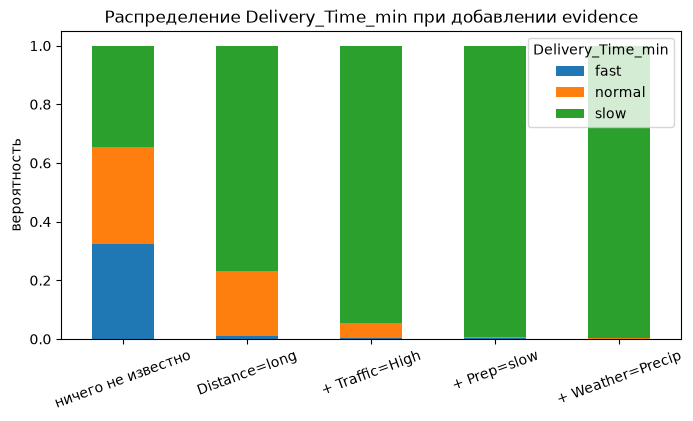

In [38]:
steps = [("ничего не известно", {}),
         ("Distance=long", {"Distance_km": "long"}),
         ("+ Traffic=High", {"Distance_km": "long", "Traffic_Level": "High"}),
         ("+ Prep=slow", {"Distance_km": "long", "Traffic_Level": "High", "Preparation_Time_min": "slow"}),
         ("+ Weather=Precip", {"Distance_km": "long", "Traffic_Level": "High", "Preparation_Time_min": "slow", "Weather": "Precipitation"})]
ev = pd.DataFrame({name: query(T, e) for name, e in steps}).T
display(ev)

ev[["fast", "normal", "slow"]].plot(kind="bar", stacked=True, figsize=(8, 4))
plt.xticks(rotation=20); plt.ylabel("вероятность"); plt.title("Распределение Delivery_Time_min при добавлении evidence")
plt.show()

3) Как дополнительная информация меняет распределение времени доставки?

    Последовательно добавляем сведения (Distance = long, затем Traffic = High и тд.) и смотрим, как меняется распределение fast / normal / slow. Ожидание: с каждым фактом вероятность slow растёт, а fast падает.

Результат:

Последовательное добавление evidence: P(slow) растёт 0.346 → 0.769 → 0.945 → 0.993 → 0.998.

Смысл: Сравнение P(A) и P(A | B) показывает, насколько информация B значима для A: чем больше разница, тем сильнее B влияет на A. Здесь все рассмотренные факторы (расстояние, пробки, время приготовления, осадки) — прямые родители Delivery, и их влияние передаётся через его CPT.

Многие строки CPT оценены по малому числу наблюдений (34 из 81 строки — меньше 10), поэтому численные значения вероятностей приблизительны - НО направление эффектов и их относительная сила согласуются с данными и со смыслом.

Эксперимент с evidence:

Интересующая переменная — Delivery_Time_min. 

Последовательно добавляем сведения: ничего не известно → Distance = long → + Traffic = High → + Prep = slow → + Weather = Precipitation.

С каждым фактом вероятность slow растёт, а fast падает, как и ожидалось. Доля normal тоже падает: 0.331 → 0.222 → 0.052 → 0.003 → 0.001. 

Вклад каждого факта в вероятность slow: расстояние +0.423, пробки +0.176, приготовление +0.048, погода +0.005. 

Первый факт даёт самый большой сдвиг, каждый следующий — всё меньше.

Объяснение через структуру сети.
 - Distance, Traffic, Preparation и Weather — прямые родители Delivery, поэтому каждый факт о них сразу меняет строку CPT Delivery, из которой берётся вероятность.
 - Чем сильнее родитель влияет на Delivery, тем больше сдвиг: расстояние в CPT почти однозначно определяет время доставки, поэтому его вклад максимален.
 - Вклады убывают из-за насыщения: после трёх фактов вероятность slow уже 0.993, и новая информация почти ничего не меняет. Это не значит, что осадки не влияют: в запросе 2 осадки сами по себе заметно повышали P(slow), просто на фоне уже известных факторов их добавочный эффект мал.
 - Когда Traffic известен, влияние погоды через пробки закрыто (цепочка Weather → Traffic → Delivery блокируется наблюдаемым Traffic), и остаётся только прямая стрелка Weather → Delivery.

Вывод. Evidence не меняет граф и CPT, а меняет распределение интересующей переменной: каждый новый факт уменьшает неопределённость. 

Эффект зависит от порядка добавления: если бы первым добавили приготовление, его вклад был бы больше, а вклад расстояния — меньше.

In [39]:
# анализ при удалении ребра
# удаляем ребро Погода->Доставка
cut_edge = cpt("Delivery_Time_min", ["Traffic_Level", "Distance_km", "Preparation_Time_min"], ess=5)

joint_cut = joint.copy()

# старый множитель (с погодой) и новый (без погоды) для каждой строки
old = joint_cut.apply(lambda r: delivery_cpt.loc[(r.Weather, r.Traffic_Level, r.Distance_km, r.Preparation_Time_min), r.Delivery_Time_min], axis=1)
new = joint_cut.apply(lambda r: cut_edge.loc[(r.Traffic_Level, r.Distance_km, r.Preparation_Time_min), r.Delivery_Time_min], axis=1)

joint_cut["P"] = joint_cut["P"] / old * new

In [40]:
ev = {"Traffic_Level": "High", "Weather": "Precipitation"}
pd.DataFrame({"Полная сеть(P(_| High и Precip))": query("Delivery_Time_min", ev),
              "без ребра Weather→Delivery": query("Delivery_Time_min", ev, data=joint_cut)})

,Полная сеть(P(_| High и Precip)),без ребра Weather→Delivery
Delivery_Time_min,,
fast,0.107,0.224
normal,0.316,0.301
slow,0.577,0.474


ВЫВОДЫ по Анализу структуры:

Удалили ребро Weather → Delivery. CPT Delivery пересчитана с тремя родителями (Traffic, Distance, Preparation), совместное распределение собрано заново. Повторён запрос 2 — P(Delivery | Traffic = High, Weather = Precipitation).

Результат 2 Запроса до удаления ребра:
        P(T)	P(T | Traffic=High)	P(T | Weather=Precip)	P(T | High и Precip)

Delivery_Time_min				

fast	0.323	          0.213         	0.265	                0.107

normal	0.331	          0.292	            0.344	                0.316

slow	0.346	          0.495	            0.391	                0.577

Результат изменился. 

P(slow) упала с 0.577 до 0.474, P(fast) выросла с 0.107 до 0.224. Без ребра сеть не учитывает погоду: осадки влияют на доставку только через пробки, а связь осадков с пробками слабая. В полной сети осадки повышали вероятность медленной доставки, без ребра — нет.

Почему структура влияет на вывод. 

Граф определяет, от каких переменных зависит каждый узел и какие CPT перемножаются. Убранное ребро — это утверждение «погода не влияет на доставку напрямую». Информация о погоде перестаёт передаваться к Delivery по этому пути, и ответ на запрос меняется. Одни и те же данные при разной структуре дают разные выводы.

Насколько уверенно можно выбирать направление рёбер только по наблюдаемым данным. 

Не очень уверенно. Связь между двумя переменными описывается CPT, и её можно разложить в обе стороны: P(A)·P(B | A) = P(B)·P(A | B).
 
Поэтому по данным нельзя отличить стрелку A→B от B→A: оба варианта дают одно и то же совместное распределение и одинаково согласуются с наблюдениями. 

Направление можно определить по данным только у коллайдеров (A→C←B), так как в них A и B независимы, но становятся зависимыми, когда известно C. В нашей сети такие структуры есть (Traffic с родителями Weather и Time_of_Day, Delivery с четырьмя родителями), но данных недостаточно для уверенного вывода: CPT Traffic почти не зависит от родителей, а у Delivery много строк CPT оценены по малому числу наблюдений. 

Поэтому направление рёбер выбрано по знаниям о предметной области: расстояние, погода и приготовление не могут зависеть от времени доставки, причина предшествует следствию.

Причинность:

полностью причинной моделью сеть считать нельзя. Направленная стрелка сама по себе не доказывает причинно-следственную связь: сеть описывает вероятностные зависимости, а структура задана нами по смыслу, а не найдена по данным (как показано в анализе структуры, данные не различают направление ребра).

Связи, которые можно считать причинными, и основание:
 - Distance → Delivery: расстояние физически определяет длину пути, оно известно раньше времени доставки, и результат (время) не может влиять на расстояние.
 - Traffic → Delivery и Weather → Delivery: есть понятный механизм (пробки и осадки снижают скорость), причина предшествует следствию.
 - Preparation → Delivery: это скорее часть времени доставки по определению (оно входит в общее время), чем причина в строгом смысле.
Связи, которые остаются гипотезами: Weather → Traffic и Time_of_Day → Traffic выбраны по здравому смыслу, но данные их слабо подтверждают (строки CPT Traffic почти одинаковы при разных погоде и времени суток).

Почему модель нельзя назвать причинной:
 -  Данные наблюдательные, а не эксперимент.
 -  Возможны скрытые факторы, которых нет в данных: ресторан, маршрут, день недели, размер заказа. Они могут создавать зависимости, которые сеть припишет другим переменным.
 -  Данные дискретизированы и, вероятно, упрощены, что ограничивает выводы.

Итог: сеть корректно описывает вероятностные зависимости и позволяет делать вывод при наличии evidence. Причинную интерпретацию можно применять только к тем связям, у которых есть механизм и временной порядок (в первую очередь расстояние и пробки к времени доставки), а не к модели целиком.